<a href="https://colab.research.google.com/github/sam-aiml/machine-learning/blob/main/chest_X_ray_Classificaton_transferLearningVgg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!mkdr -p ~/ .kaggle
!cp kaggle\ \(3\).json

/bin/bash: line 1: mkdr: command not found
cp: missing destination file operand after 'kaggle (3).json'
Try 'cp --help' for more information.


In [ ]:
#!/bin/bash
!kaggle datasets download navoneel/brain-mri-images-for-brain-tumor-detection

Dataset URL: https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection
License(s): copyright-authors
brain-mri-images-for-brain-tumor-detection.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
import zipfile
zip_ref = zipfile.ZipFile('/content/brain-mri-images-for-brain-tumor-detection.zip','r')
zip_ref.extractall('/content')
zip_ref.close()

In [ ]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Conv2D,Dense,MaxPooling2D,Dropout
from keras.layers import BatchNormalization,Flatten


In [ ]:
import os
import cv2
import numpy as np
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications.vgg16 import preprocess_input

# Dataset folders
path_yes = '/content/yes'
path_no = '/content/no'

# Supported image formats
valid_extensions = (
    '.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tiff'
)

# Store images and labels
x = []
y = []

# Load images from the YES folder
for file_name in tqdm(os.listdir(path_yes), desc="Loading YES images"):

    if not file_name.lower().endswith(valid_extensions):
        continue

    full_path = os.path.join(path_yes, file_name)

    img = cv2.imread(full_path)

    if img is None:
        print(f"Skipping unreadable image: {file_name}")
        continue

    # Resize to the VGG16 input size
    img = cv2.resize(img, (224, 224))

    # OpenCV loads BGR; convert to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    x.append(img)
    y.append('Y')


# Load images from the NO folder
for file_name in tqdm(os.listdir(path_no), desc="Loading NO images"):

    if not file_name.lower().endswith(valid_extensions):
        continue

    full_path = os.path.join(path_no, file_name)

    img = cv2.imread(full_path)

    if img is None:
        print(f"Skipping unreadable image: {file_name}")
        continue

    # Resize to the VGG16 input size
    img = cv2.resize(img, (224, 224))

    # OpenCV loads BGR; convert to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    x.append(img)
    y.append('N')


# Convert images to a NumPy array
x = np.array(x, dtype=np.float32)

# Apply VGG16 ImageNet preprocessing
x = preprocess_input(x)



# Display dataset information
print("\nDataset loaded successfully!")
print("Images shape:", x.shape)


# Check the dataset
assert len(x) == len(y), "Images and labels do not match!"
assert len(x) > 0, "No images were loaded!"
#assert len(y.classes_) == 2, "Expected two classes!"
assert np.isfinite(x).all(), "Images contain invalid numerical values!"
print("All basic checks passed!")

Loading NO images: 100%|██████████| 98/98 [00:00<00:00, 508.00it/s]



Dataset loaded successfully!
Images shape: (253, 224, 224, 3)
All basic checks passed!


In [ ]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Convert text labels into numbers
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Apply one-hot encoding
y_onehot = to_categorical(y_encoded, num_classes=2)

print("Classes:", le.classes_)
print("Encoded labels:", y_encoded[:5])
print("One-hot labels:\n", y_onehot[:5])

Classes: ['N' 'Y']
Encoded labels: [1 1 1 1 1]
One-hot labels:
 [[0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]


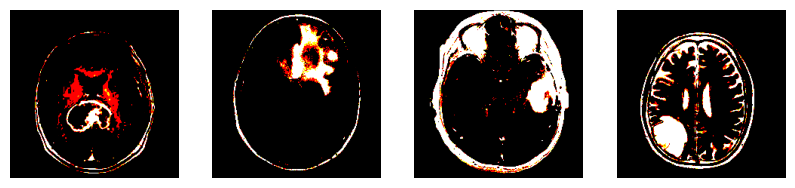

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,19))
for i in range(4):
  plt.subplot(1,4,i+1)
  plt.imshow(x[i], cmap ="gray")
  plt.axis('off')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y_onehot,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (202, 224, 224, 3)
X_test: (51, 224, 224, 3)
y_train: (202, 2)
y_test: (51, 2)


In [ ]:
from keras.applications import vgg16
img_rows,img_cols = 224,224
vgg = vgg16.VGG16(weights = 'imagenet', include_top=False,input_shape= (img_rows,img_cols,3))
for layers in vgg.layers:
  layers.trainable = False

#print the layers
for (i, layer) in enumerate(vgg.layers):
    print(str(i)+ " "+ layer.__class__.__name__, layer.trainable)


0 InputLayer False
1 Conv2D False
2 Conv2D False
3 MaxPooling2D False
4 Conv2D False
5 Conv2D False
6 MaxPooling2D False
7 Conv2D False
8 Conv2D False
9 Conv2D False
10 MaxPooling2D False
11 Conv2D False
12 Conv2D False
13 Conv2D False
14 MaxPooling2D False
15 Conv2D False
16 Conv2D False
17 Conv2D False
18 MaxPooling2D False


In [ ]:
def lw(bottom_model, num_classes):
  top_model = bottom_model.output
  top_model = GlobalAveragePooling2D()(top_model)
  top_model = Dense(1024, activation='relu')(top_model)
  top_model = Dense(848, activation='relu')(top_model)
  top_model = Dense(512, activation='relu')(top_model)
  top_model = Dense(num_classes, activation='softmax')(top_model)
  return top_model


In [ ]:
from keras.models import Model
from keras.layers import GlobalAveragePooling2D
from keras.models import Sequential
from keras.layers import Conv2D,Dense,MaxPooling2D,Dropout

num_classes = 2
FC_Head = lw(vgg, num_classes)
model = Model(inputs = vgg.input, outputs = FC_Head)
print(model.summary())

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 848)            │       869,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       434,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 16,544,914 (63.11 MB)

 Trainable params: 1,830,226 (6.98 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

None


In [ ]:

model.compile(optimizer ='Adam', loss = 'categorical_crossentropy',metrics = ['accuracy'] )

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    min_delta = 0.001,
    restore_best_weights=True,
    verbose =1
)

In [ ]:
model_history = model.fit(X_train, y_train,validation_data=(X_train,y_train),validation_split=0.2,epochs = 20,callbacks=[early_stop])

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.5693 - loss: 3.2511 - val_accuracy: 0.8366 - val_loss: 0.5551
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 274ms/step - accuracy: 0.7970 - loss: 0.6280 - val_accuracy: 0.7079 - val_loss: 1.2800
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 268ms/step - accuracy: 0.8119 - loss: 0.6147 - val_accuracy: 0.7129 - val_loss: 0.6342
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 275ms/step - accuracy: 0.8218 - loss: 0.3944 - val_accuracy: 0.8812 - val_loss: 0.2505
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 274ms/step - accuracy: 0.9109 - loss: 0.2008 - val_accuracy: 0.9554 - val_loss: 0.1412
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 275ms/step - accuracy: 0.9554 - loss: 0.1114 - val_accuracy: 0.9554 - val_loss: 0.0864
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 276ms/step - accuracy: 0.9653 - loss: 0.0697 - val_accuracy: 0.9901 - val_loss: 0.0367
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 284ms/step - accuracy: 0.9950 - loss: 0.0306 - val_accuracy: 0.9950 - val_loss: 0

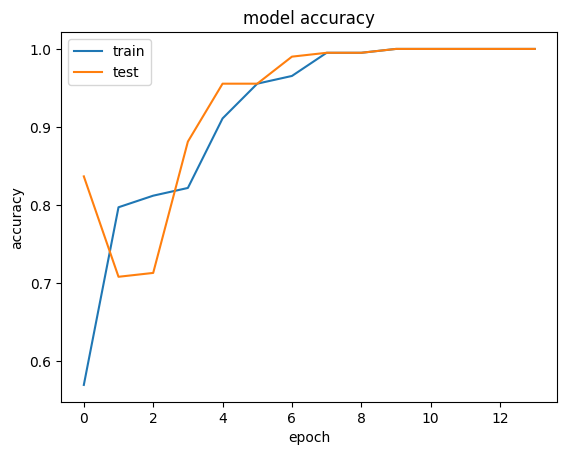

In [ ]:
plt.plot(model_history.history['accuracy'])
plt.plot(model_history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','test'], loc = 'upper left')
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.9020 - loss: 0.6455
Test Accuracy: 90.19607901573181 %


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_pred = model.predict(X_test)

y_true = np.argmax(y_test, axis=1)
y_pred_classes = np.argmax(y_pred, axis=1)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_classes))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred_classes,
    target_names=le.classes_
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 813ms/step
Confusion Matrix:
[[17  3]
 [ 2 29]]

Classification Report:
              precision    recall  f1-score   support

           N       0.89      0.85      0.87        20
           Y       0.91      0.94      0.92        31

    accuracy                           0.90        51
   macro avg       0.90      0.89      0.90        51
weighted avg       0.90      0.90      0.90        51



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score, auc

In [ ]:

# Predict probabilities
y_pred_prob = model.predict(X_test)

# Convert one-hot encoded true labels into class numbers
y_true = np.argmax(y_test, axis=1)

positive_class_index = list(le.classes_).index('Y')
y_pneumonia_prob = y_pred_prob[:, positive_class_index]

# Actual labels: 1 = Pneumonia, 0 = Normal
y_true_binary = (y_true == positive_class_index).astype(int)


fpr, tpr, thresholds = roc_curve(
    y_true_binary,
    y_pneumonia_prob
)


roc_auc = roc_auc_score(
    y_true_binary,
    y_pneumonia_prob
)

print("ROC-AUC Score:", round(roc_auc, 4))


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
ROC-AUC Score: 0.9411


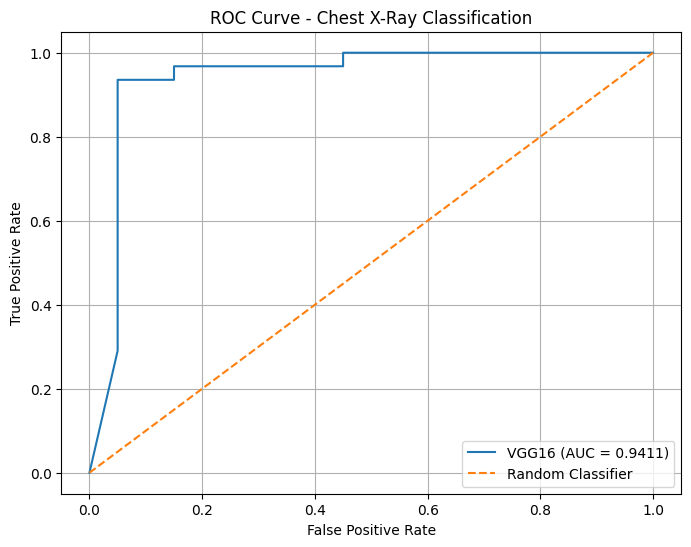

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'VGG16 (AUC = {roc_auc:.4f})'
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Chest X-Ray Classification')

plt.legend(loc='lower right')
plt.grid(True)
plt.show()
